# Row-level satellite collision risk: modeling experiment

Estimate **each message's `log10(Pc)`** from the 12 permitted predictors. This is supervised reconstruction of a calculated risk label, not prediction of observed collision outcomes or the final risk of an event.

This notebook uses the frozen 70/15/15 **event** split from the EDA. Preprocessing and models fit on training events only. Validation chooses the model. Holdout evaluation occurs once, after the model is frozen, and is cached thereafter.

## Experiment

| Run | Model | Purpose |
|---|---|---|
| B0 | Median-target dummy | MAE baseline |
| B1 | Mean-target dummy | Squared-error baseline |
| M1 | Median-imputed HGB | Missingness indicators and unknown-safe category encoding |
| M2 | Native-NaN HGB | Same feature flags, encoding, and model settings |
| M3 | Better M1/M2 preprocessing + three geometry features | Test additional physical structure |
| A0 | Selected architecture without `max_risk_estimate` | Diagnostic ablation, not a selection candidate |

The earlier EDA exposed aggregate full-training counts. This is disclosed; no held-out relationships or results are used for model selection. **Test `risk` is never loaded.**

Start with `requirements-model.txt` installed and the EDA artifacts present. Run **Restart Kernel → Run All**. Training is cached by data, split, code, and dependency fingerprints; subsequent runs reuse the same trained models.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import precision_recall_curve

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'data/train_data.csv').is_file() and (p/'src/model.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch from the repository root or notebooks directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from src.experiment import run_experiment
from src.model import FEATURES, PARAMETERS, load_bundle, predict_log10_pc, TIERS
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
SEED = 42
print('Allowed predictors:', FEATURES)
display(pd.Series(PARAMETERS, name='value').to_frame())

Allowed predictors: ['time_to_tca', 'miss_distance', 'relative_speed', 'relative_position_r', 'relative_position_t', 'relative_position_n', 'c_object_type', 'c_sigma_r', 't_sigma_r', 'max_risk_estimate', 'F10', 'AP']


,value
loss,squared_error
learning_rate,0.05
max_iter,300
max_leaf_nodes,31
min_samples_leaf,20
l2_regularization,1.0
early_stopping,False
random_state,42


## 1. Run or reuse the controlled experiment

`FINALIZE=False` trains/selects using validation only. Set it to `True` deliberately to freeze the model, run compatibility checks, open the holdout **once**, and produce test exports. If an evaluated run already exists, either setting reuses the saved holdout report without recomputing holdout predictions. A different code/data/model configuration cannot automatically reuse this holdout.

All HGB runs use 300 iterations with automatic early stopping disabled: an internal row-random validation split would violate event separation. No oversampling, class weights, PCA, scaling, or target-floor removal is used.

**Selection:** among M1–M3 within 1% of the lowest validation raw-log-risk RMSE, prefer higher Pc-critical F2 at −4, then fewer false positives, lower MAE, and the simpler model. This is our balanced default, not the organizer's scoring formula.

In [2]:
FINALIZE = False
experiment = run_experiment(ROOT, finalize=FINALIZE)
run_dir = Path(experiment['run_dir'])
selection = experiment['selection']
comparison = experiment['comparison']
selected = selection['selected']
print('Run:', selection['run_id'], '| selected:', selected, '| M3 preprocessing parent:', selection['derived_parent'])
print('Compatibility checks:', selection['checks'])
splits = pd.read_csv(ROOT/'artifacts/event_splits.csv')
display(splits.groupby('partition').size().rename('events').to_frame())

B0: fitting or loading cached model


B0: validation RMSE=10.1568, critical recall=0.0, F2=0.0


B1: fitting or loading cached model


B1: validation RMSE=10.0694, critical recall=0.0, F2=0.0


M1: fitting or loading cached model


...

A0: fitting or loading cached model


A0: validation RMSE=5.7622, critical recall=0.018691588785046728, F2=0.022935779816513763


Complete: M3 selected; holdout completed/cached; elapsed 0.3s


Run: 87c8704204c5 | selected: M3 | M3 preprocessing parent: M2
Compatibility checks: {'passed': True, 'checks': ['target and ID exclusion', 'column-order invariance', 'save/load equivalence', 'unknown category', 'missing optional values/columns', 'invalid required input rejection', 'early stopping disabled']}


,events
partition,
holdout,1972
train,9200
validation,1971


## 2. Validation comparison and selection

Raw log-risk RMSE/MAE measure label reconstruction. Critical precision/recall/F2 use the fixed `risk >= -4` threshold. **Average precision (AP)** uses continuous prediction scores; it is not a calibration score or trapezoidal PR area. Every rare-class result needs its positive count.

Both preprocessing variants retain raw extreme sigmas and include the same missingness and `sigma > 1e6 m` flags. M3 adds absolute radial position, combined radial sigma under independent errors, and their ratio. These features are calculated before imputation; an invalid or zero denominator remains missing.

,RMSE,MAE,precision,recall,F2,AP,TP,FP,FN,positive_rows,fit_and_evaluation_seconds
model,,,,,,,,,,,
B0,10.156779,9.510402,NaN,0.000000,0.000000,0.004393,0,0,107,107,0.33
B1,10.069372,9.556982,NaN,0.000000,0.000000,0.004393,0,0,107,107,0.27
M1,5.410627,3.758468,0.228070,0.364486,0.325543,0.231534,39,132,68,107,2.70
M2,5.395964,3.752458,0.246835,0.364486,0.332765,0.237541,39,119,68,107,2.81
M3,5.272757,3.509661,0.313253,0.485981,0.437710,0.299781,52,114,55,107,2.79
A0,5.762250,3.870106,0.250000,0.018692,0.022936,0.064266,2,6,105,107,2.63


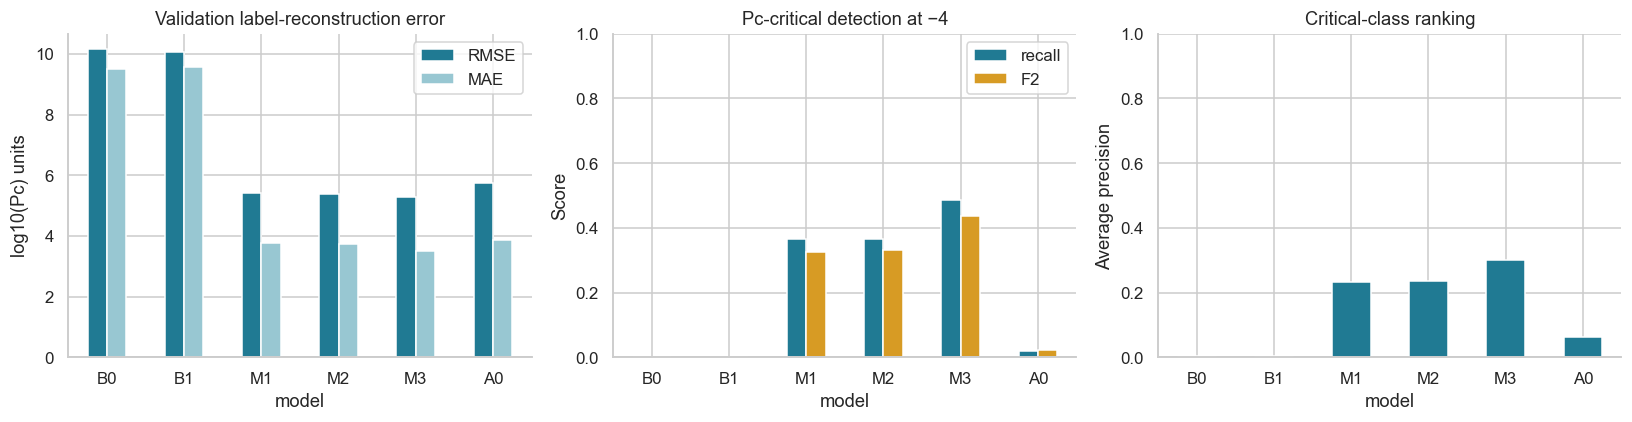

**Selected M3.** Validation RMSE improves by **47.6%** over the mean dummy. Critical detection must still be judged independently of that improvement.

In [3]:
comparison_table = pd.DataFrame([
    {'model': name, 'RMSE': result['validation']['rmse'], 'MAE': result['validation']['mae'],
     'precision': result['validation']['pc_critical']['precision'],
     'recall': result['validation']['pc_critical']['recall'],
     'F2': result['validation']['pc_critical']['f2'],
     'AP': result['validation']['pc_critical']['average_precision'],
     'TP': result['validation']['pc_critical']['tp'], 'FP': result['validation']['pc_critical']['fp'],
     'FN': result['validation']['pc_critical']['fn'], 'positive_rows': result['validation']['pc_critical']['positives'],
     'fit_and_evaluation_seconds': result['elapsed_seconds']}
    for name,result in comparison.items()]).set_index('model')
display(comparison_table)
fig, axes = plt.subplots(1,3,figsize=(15,4))
comparison_table[['RMSE','MAE']].plot.bar(ax=axes[0],color=['#207a93','#98c7d2'])
comparison_table[['recall','F2']].plot.bar(ax=axes[1],color=['#207a93','#d79b24'])
comparison_table.AP.plot.bar(ax=axes[2],color='#207a93')
axes[0].set(title='Validation label-reconstruction error',ylabel='log10(Pc) units')
axes[1].set(title='Pc-critical detection at −4',ylabel='Score',ylim=(0,1))
axes[2].set(title='Critical-class ranking',ylabel='Average precision',ylim=(0,1))
for ax in axes: ax.tick_params(axis='x',rotation=0)
fig.tight_layout(); plt.show()
baseline = comparison['B1']['validation']['rmse']
gain = 100*(baseline-comparison[selected]['validation']['rmse'])/baseline
display(Markdown(f'**Selected {selected}.** Validation RMSE improves by **{gain:.1f}%** over the mean dummy. '
                 'Critical detection must still be judged independently of that improvement.'))

## 3. Selected-model errors and rare-class ranking

Only validation labels are loaded for these plots. Features are loaded with an explicit allowlist and joined to cached validation predictions using original CSV row IDs. Holding out an event means all its messages stay out of training.

The −30 floor is retained. A regressor can improve average error while still missing critical rows. Examine the scatter, floor/non-floor slices, and high-risk counts together.

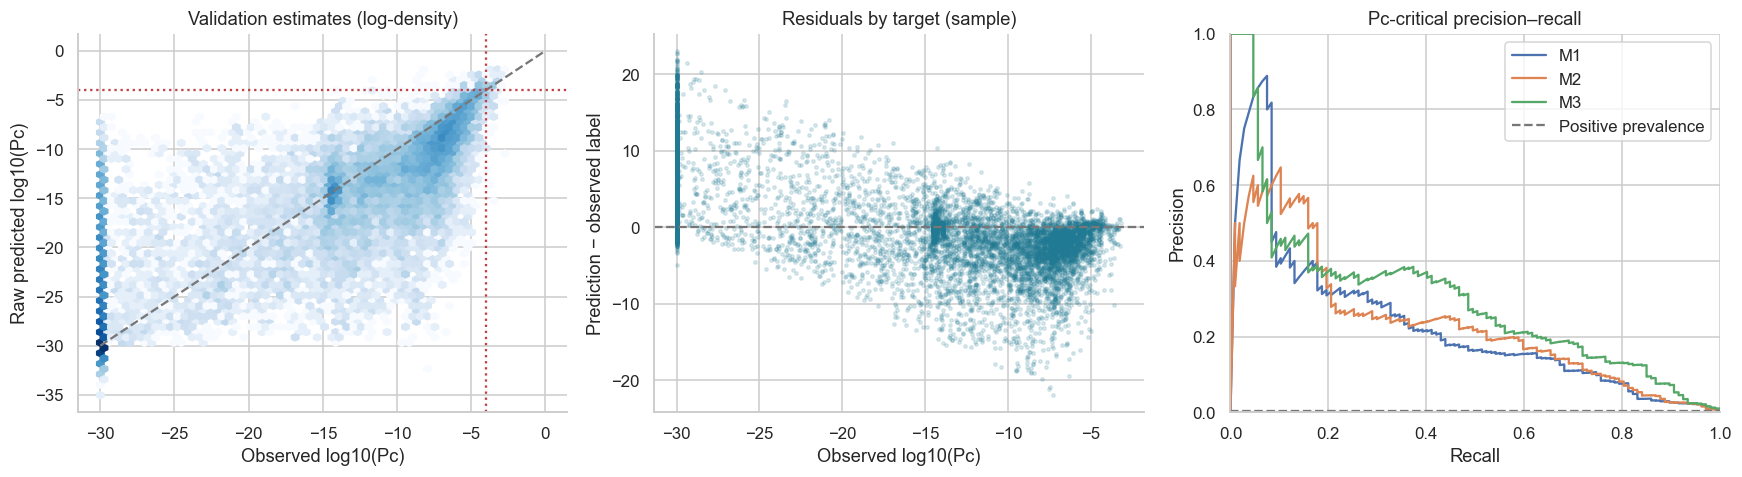

In [4]:
predictions = pd.read_csv(run_dir/f'{selected}_validation_predictions.csv')
telemetry = pd.read_csv(ROOT/'data/train_data.csv',usecols=['event_id',*FEATURES])
telemetry['row_id'] = np.arange(len(telemetry))
validation = predictions.merge(telemetry,on=['row_id','event_id'],how='left',validate='one_to_one')
del telemetry
assert set(validation.event_id) == set(splits.loc[splits.partition.eq('validation'),'event_id'])
assert set(validation.event_id).isdisjoint(set(splits.loc[splits.partition.eq('train'),'event_id']))
validation['error'] = validation.predicted_log10_pc_raw - validation.risk
plot_sample = validation.sample(min(12000,len(validation)),random_state=SEED)
fig, axes = plt.subplots(1,3,figsize=(16,4.5))
axes[0].hexbin(validation.risk,validation.predicted_log10_pc_raw,gridsize=55,bins='log',mincnt=1,cmap='Blues')
axes[0].plot([-30,0],[-30,0],color='#777777',linestyle='--')
axes[0].axhline(-4,color='#bf4145',linestyle=':'); axes[0].axvline(-4,color='#bf4145',linestyle=':')
axes[0].set(xlabel='Observed log10(Pc)',ylabel='Raw predicted log10(Pc)',title='Validation estimates (log-density)')
axes[1].scatter(plot_sample.risk,plot_sample.error,s=5,alpha=.15,color='#207a93')
axes[1].axhline(0,color='#777777',linestyle='--')
axes[1].set(xlabel='Observed log10(Pc)',ylabel='Prediction − observed label',title='Residuals by target (sample)')
truth = validation.risk.ge(-4)
for name in ['M1','M2','M3']:
    p = pd.read_csv(run_dir/f'{name}_validation_predictions.csv')
    assert np.array_equal(p.row_id,predictions.row_id)
    precision, recall, _ = precision_recall_curve(truth,p.predicted_log10_pc_raw)
    axes[2].plot(recall,precision,label=name)
axes[2].axhline(truth.mean(),color='#777777',linestyle='--',label='Positive prevalence')
axes[2].set(xlabel='Recall',ylabel='Precision',title='Pc-critical precision–recall',xlim=(0,1),ylim=(0,1))
axes[2].legend(); fig.tight_layout(); plt.show()

## 4. Separate probability risk from distance overrides

The combined policy is critical if estimated `log10(Pc) >= -4` **or** observed miss distance is below 1,000 m. Distance alone is elevated at exactly 1,000 m and 5,000 m. Do not interpret good combined-tier results as proof that Pc predictions are good.

Matrices show observed-policy labels versus predicted-policy labels. `needs_review` is a reserved category for invalid inputs; the current scored dataset has valid required telemetry.

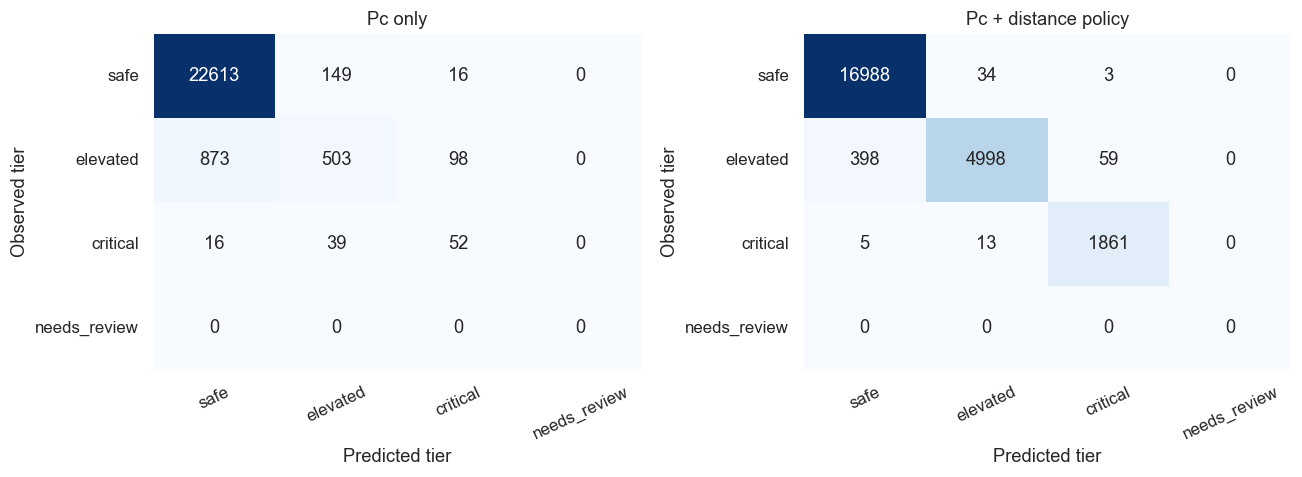

,tp,fp,fn,tn,positives,predicted_positives,precision,recall,f2,average_precision
level,,,,,,,,,,
all messages,52,114,55,24138,107,166,0.313253,0.485981,0.43771,0.299781
latest pre-TCA message per event,0,2,1,1968,1,2,0.000000,0.000000,0.00000,0.333333


Latest-message Pc false alerts / 1,000 events: 1.0147133434804667
Latest-message combined policy: {'tp': 144, 'fp': 2, 'fn': 0, 'tn': 1825, 'positives': 144, 'predicted_positives': 146, 'precision': 0.9863013698630136, 'recall': 1.0, 'f2': 0.997229916897507, 'false_alerts_per_1000_events': 1.0147133434804667}


In [5]:
selected_metrics = comparison[selected]['validation']
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for ax,key,title in zip(axes,['pc_confusion_matrix','combined_confusion_matrix'],['Pc only','Pc + distance policy']):
    matrix = np.asarray(selected_metrics[key])
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',xticklabels=TIERS,yticklabels=TIERS,ax=ax,cbar=False)
    ax.set(xlabel='Predicted tier',ylabel='Observed tier',title=title)
    ax.tick_params(axis='x',rotation=25); ax.tick_params(axis='y',rotation=0)
fig.tight_layout(); plt.show()
display(pd.DataFrame([
    {'level':'all messages',**selected_metrics['pc_critical']},
    {'level':'latest pre-TCA message per event',**selected_metrics['latest_pc']['pc_critical']},
]).set_index('level'))
print('Latest-message Pc false alerts / 1,000 events:',selected_metrics['latest_pc']['false_alerts_per_1000_events'])
print('Latest-message combined policy:', selected_metrics['latest_combined'])

## 5. Error slices and event-bootstrap intervals

Slices overlap: their counts must not be added. Particularly inspect the test-horizon slice (`time_to_tca >= 2 days`), since supplied test messages are all more than two days before TCA. Small slices and undefined metrics remain visible.

Bootstrap intervals resample **whole events**, retaining all messages in every sampled event. They describe sampling variability of metrics for this fitted model, not physical Pc uncertainty or uncertainty from retraining. No coverage guarantee under distribution shift is claimed.

,rows,events,mae,rmse,pc_critical.positives,pc_critical.recall,pc_critical.f2
slice,,,,,,,
all,24359,1971,3.509661,5.272757,107,0.485981,0.437710
floor_-30,9933,1290,3.181626,5.465558,0,NaN,NaN
non_floor,14426,1832,3.735529,5.135797,107,0.485981,0.437710
risk_ge_-6,1581,311,2.133604,3.283073,107,0.485981,0.449827
risk_ge_-4,107,23,1.440382,2.530156,107,0.485981,0.541667
near_-6_+-0.5,1410,360,2.857069,3.939313,0,NaN,NaN
near_-4_+-0.5,225,46,1.428312,2.349376,72,0.333333,0.332410
test_horizon_ge_2_days,16819,1805,3.704219,5.379908,92,0.554348,0.478424
time/0_to_24h,3851,1406,2.726465,4.702004,2,0.000000,0.000000


,low_95,high_95,valid_replicates,undefined_replicates
mae,3.397704,3.640299,200.0,0.0
rmse,5.116006,5.457304,200.0,0.0
pc_recall,0.322173,0.649168,200.0,0.0
pc_f2,0.281013,0.569231,200.0,0.0
latest_pc_recall,0.000000,0.000000,128.0,72.0
latest_pc_f2,0.000000,0.000000,128.0,72.0
latest_false_alerts_per_1000_events,0.000000,3.044140,200.0,0.0


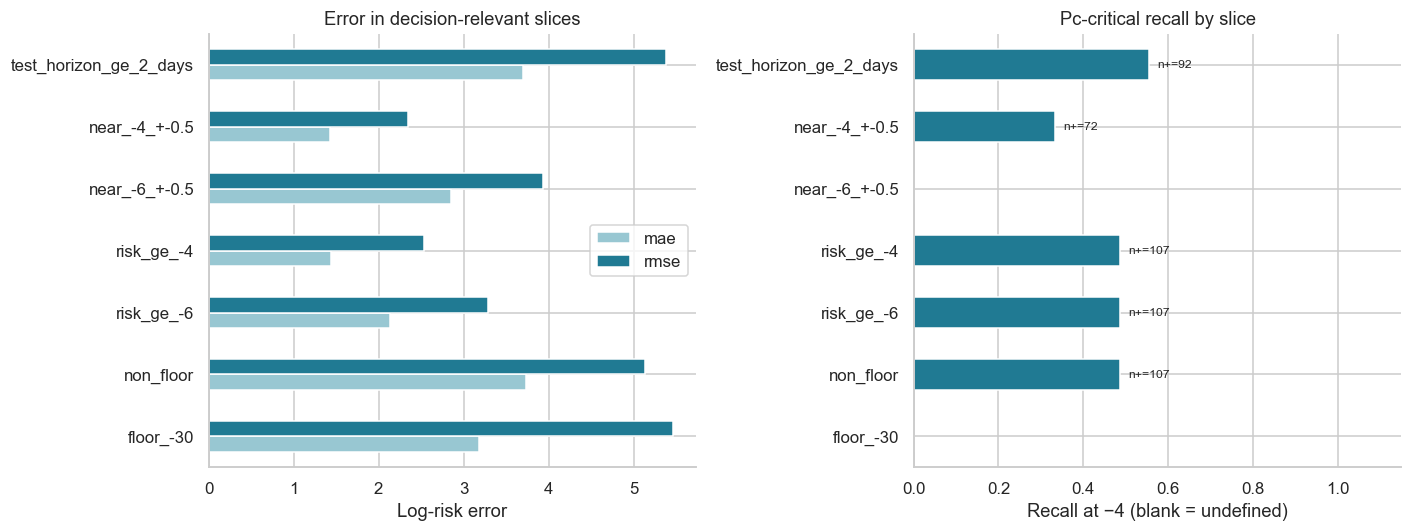

In [6]:
details = experiment['validation_detail']
slices = pd.json_normalize([{'slice':name,**value} for name,value in details['slices'].items()]).set_index('slice')
with pd.option_context('display.max_rows',50):
    display(slices[['rows','events','mae','rmse','pc_critical.positives','pc_critical.recall','pc_critical.f2']])
bootstrap = pd.DataFrame(details['bootstrap']['intervals']).T
display(bootstrap)
focus = slices.loc[['floor_-30','non_floor','risk_ge_-6','risk_ge_-4','near_-6_+-0.5','near_-4_+-0.5','test_horizon_ge_2_days']]
fig, axes = plt.subplots(1,2,figsize=(13,5))
focus[['mae','rmse']].plot.barh(ax=axes[0],color=['#98c7d2','#207a93'])
focus['pc_critical.recall'].plot.barh(ax=axes[1],color='#207a93')
axes[0].set(xlabel='Log-risk error',ylabel='',title='Error in decision-relevant slices')
axes[1].set(xlabel='Recall at −4 (blank = undefined)',ylabel='',title='Pc-critical recall by slice',xlim=(0,1.15))
for i,(_,row) in enumerate(focus.iterrows()):
    x = row['pc_critical.recall']
    if pd.notna(x): axes[1].text(x+.02,i,f"n+={int(row['pc_critical.positives'])}",va='center',fontsize=8)
fig.tight_layout(); plt.show()

## 6. Dependence on the upstream risk estimate

`max_risk_estimate` is explicitly allowed and is already risk-derived information. A0 retrains the selected architecture after removing it. The resulting performance change measures model dependence on that feature; it does not prove target leakage. A0 is diagnostic and cannot silently replace the selected model after inspecting the holdout.

In [7]:
display(comparison_table.loc[[selected,'A0']])
rmse_delta = comparison['A0']['validation']['rmse']-selected_metrics['rmse']
display(Markdown(f'Removing `max_risk_estimate` changes validation RMSE by **{rmse_delta:+.4f}**. '
                 'Compare recall and false positives as well as error before interpreting the feature’s contribution.'))

,RMSE,MAE,precision,recall,F2,AP,TP,FP,FN,positive_rows,fit_and_evaluation_seconds
model,,,,,,,,,,,
M3,5.272757,3.509661,0.313253,0.485981,0.437710,0.299781,52,114,55,107,2.79
A0,5.762250,3.870106,0.250000,0.018692,0.022936,0.064266,2,6,105,107,2.63


Removing `max_risk_estimate` changes validation RMSE by **+0.4895**. Compare recall and false positives as well as error before interpreting the feature’s contribution.

## 7. Frozen holdout result, if finalized

This cell only displays the saved result returned by the experiment; it does not predict the holdout or choose a model. If no result is present, the holdout has not been opened. Do not use these results for another tuning cycle.

In [8]:
holdout = experiment['holdout']
if holdout is None:
    print('Holdout not opened. Review validation first, then deliberately finalize via the option above or scripts/train.py --finalize.')
else:
    h = holdout['metrics']
    display(pd.DataFrame([{'rows':h['rows'],'events':h['events'],'MAE':h['mae'],'RMSE':h['rmse'],**h['pc_critical']}]))
    display(pd.DataFrame(holdout['bootstrap']['intervals']).T)
    print('Latest-event Pc:',h['latest_pc'])
    print('Latest-event combined policy:',h['latest_combined'])
    print('Saved once; model selection was completed before these values were computed.')

,rows,events,MAE,RMSE,tp,fp,fn,tn,positives,predicted_positives,precision,recall,f2,average_precision
0,24689,1972,3.474393,5.182446,39,109,66,24475,105,148,0.263514,0.371429,0.34331,0.223494


,low_95,high_95,valid_replicates,undefined_replicates
mae,3.364486,3.588256,200.0,0.0
rmse,5.024150,5.326784,200.0,0.0
pc_recall,0.196792,0.568871,200.0,0.0
pc_f2,0.184541,0.508202,200.0,0.0
latest_pc_recall,0.000000,0.000000,179.0,21.0
latest_pc_f2,0.000000,0.000000,179.0,21.0
latest_false_alerts_per_1000_events,0.000000,1.521298,200.0,0.0


Latest-event Pc: {'rows': 1972, 'events': 1972, 'mae': 2.742113026541974, 'rmse': 4.572519807035503, 'pc_critical': {'tp': 0, 'fp': 1, 'fn': 2, 'tn': 1969, 'positives': 2, 'predicted_positives': 1, 'precision': 0.0, 'recall': 0.0, 'f2': 0.0, 'average_precision': 0.06565656565656565}, 'false_alerts_per_1000_events': 0.5070993914807302}
Latest-event combined policy: {'tp': 128, 'fp': 0, 'fn': 1, 'tn': 1843, 'positives': 129, 'predicted_positives': 128, 'precision': 1.0, 'recall': 0.9922480620155039, 'f2': 0.9937888198757764, 'false_alerts_per_1000_events': 0.0}
Saved once; model selection was completed before these values were computed.


## 8. Prediction handoff and output integrity

`predict_log10_pc(frame)` returns raw finite log-risk estimates in input order and ignores labels/IDs as predictors. For repeated app calls, load the bundle once and pass it as the second argument. The serialized bundle contains both preprocessing and the estimator.

The export separately stores raw predictions, display-clipped predictions, estimated Pc, clipping flags, and model version. Exponentiating the log-risk point estimate does not generally recover a conditional mean of physical Pc. Test predictions are not evaluated against test labels.

In [9]:
model = load_bundle(ROOT/'artifacts/selected_model.joblib')
fixture = pd.read_csv(ROOT/'tests/fixtures/telemetry.csv')
expected = pd.read_csv(ROOT/'tests/fixtures/expected_predictions.csv')
raw = predict_log10_pc(fixture,model)
np.testing.assert_allclose(raw,expected.predicted_log10_pc_raw,rtol=1e-12,atol=1e-12)
np.testing.assert_array_equal(raw,predict_log10_pc(fixture.assign(risk=999),model))
assert 'risk' not in fixture
print('PASS: label-free fixture, prediction consistency, and label independence.')
display(expected[['event_id','predicted_log10_pc_raw','predicted_pc','risk_tier']])
export_path = ROOT/'outputs/test_predictions.csv'
if holdout is not None and export_path.exists():
    exported = pd.read_csv(export_path)
    test_ids = pd.read_csv(ROOT/'data/test_data.csv',usecols=['event_id'])
    assert len(exported)==len(test_ids)
    np.testing.assert_array_equal(exported.event_id,test_ids.event_id)
    np.testing.assert_array_equal(exported.row_id,np.arange(len(test_ids)))
    assert np.isfinite(exported.predicted_log10_pc_raw).all()
    assert exported.predicted_pc.between(0,1,inclusive='right').all()
    assert exported.model_version.eq(model['metadata']['model_version']).all()
    print(f'PASS: {len(exported):,} test rows in original order; finite predictions, correct model version.')
else:
    print('Test export is produced after finalization, or independently with scripts/predict.py.')
print('Report: reports/model_report.md')

PASS: label-free fixture, prediction consistency, and label independence.


,event_id,predicted_log10_pc_raw,predicted_pc,risk_tier
0,0,-24.664128,2.167067e-25,safe
1,0,-24.900839,1.256495e-25,safe
2,0,-26.003726,9.914575e-27,safe
3,0,-26.185497,6.523830e-27,safe
4,0,-25.694693,2.019792e-26,safe
5,2,-12.126749,7.468799e-13,safe
6,2,-12.126749,7.468799e-13,safe
7,2,-28.011321,9.742694e-29,safe


PASS: 24,484 test rows in original order; finite predictions, correct model version.
Report: reports/model_report.md


## 9. Research context and next decisions

This bounded experiment tests the directly transferable ideas from the review. It does not replicate published forecasting benchmarks with different inputs or targets.

| Research | What we use / defer |
|---|---|
| [Uriot et al., ESA challenge analysis](https://www.honda-ri.de/pubs/pdf/4688.pdf) | Strong baselines, trees, missing-value handling, and disciplined validation. Its earlier observed-risk predictor is prohibited here. |
| [Tulczyjew et al., satellite risk models](https://www.sciencedirect.com/science/article/pii/S246889672100094X) | A separate alert classifier may be a future experiment if regression misses critical rows. No hard gating is added here. |
| [Catulo et al., Bayesian HMM](https://arxiv.org/pdf/2311.10633) | Risk truncation and uncertainty matter; an HMM using risk histories cannot be copied under this allowlist. |
| [Grinsztajn et al., tabular benchmarks](https://arxiv.org/abs/2207.08815) | Supports a practical tree baseline, not universal superiority. |
| [Hollmann et al., TabPFN](https://www.nature.com/articles/s41586-024-08328-6) | Modern neural tabular models are credible later benchmarks. |
| [Prokhorenkova et al., CatBoost](https://proceedings.neurips.cc/paper_files/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html) | An optional future challenger; one small categorical field does not require it now. |
| [Josse et al., missing-value prediction](https://arxiv.org/abs/1902.06931) | Compare native missingness with simple imputation rather than assuming elaborate reconstruction helps. |
| [Saito and Rehmsmeier, precision–recall analysis](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432) | Report rare-class detection and false positives alongside regression. |
| [Romano et al., conformalized quantile regression](https://arxiv.org/abs/1905.03222) | Possible future intervals; event dependence and shift require care. Current bootstrap intervals are metric intervals only. |
| [TCN–Transformer preprint](https://arxiv.org/html/2609.13191v1) | Richer inputs and next-CDM forecasting differ from our row target. |

**Next decisions must use validation, not holdout feedback.** If Pc recall remains inadequate, propose a separately validated alert classifier or a new evaluation protocol. Its probability of belonging to the critical class is not Pc and must never replace Pc in the UI. Preserve the completed run, its split and model fingerprints, and the one-time holdout ledger.